# Comparing LeNet-Style CNN and Mini-VGG on CIFAR-10
Berkay Aydin - [Student ID removed]

I wanted to compare two CNN models that use different approaches to learning image features: LeNet-Style CNN and Mini-VGG.

LeNet-Style has a simpler structure with two convolution layers, while Mini-VGG uses several smaller convolution layers grouped together. I was interested in whether having more layers would actually improve classification accuracy, and how much difference it would make in training time and model size.

I trained both models on CIFAR-10 and compared their results. I also experimented with model size, dropout, and optimizers to understand how these changes affect performance.

## 1. Experiment Settings

I kept the main training settings the same for both models to make the comparison fair. Both use the same dataset, data splits, batch size, number of epochs, loss function, and optimizer.

I used 8 epochs and a batch size of 128. I also set a random seed so I could repeat the experiments more consistently.

For cross-validation, I divided the training data into three parts. Each model was trained three times using different training and validation splits. I then selected the best version of each model based on validation accuracy.

I kept the test set separate until the model selection was finished.

In [18]:
import random
import time
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# I set a seed to make my results easier to reproduce.
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# I use the same settings for both models.
EPOCHS = 8
BATCH_SIZE = 128
FOLDS = 3
LEARNING_RATE = 0.02
DROPOUT = 0.2
NUM_WORKERS = 2

# I use the GPU if one is available.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

Device: cuda


## 2. Loading CIFAR-10

I used the CIFAR-10 dataset, which has 50,000 training images and 10,000 test images. Each image is 32 × 32 pixels and belongs to one of ten classes.

I loaded the dataset using PyTorch and converted the images into tensors so the models could process them. I also normalized the color values to make training more consistent.

I used the same normalization for the training and test images. I decided not to use data augmentation because I wanted to keep the comparison between the two models simple and focus on their architectures.

In [19]:
# I converted the images to tensors and normalized the colors.
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# I loaded the training and test images separately.
train_data = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

class_names = train_data.classes
labels = np.array(train_data.targets)

print("Training images:", len(train_data))
print("Test images:", len(test_data))
print("Classes:", class_names)


Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


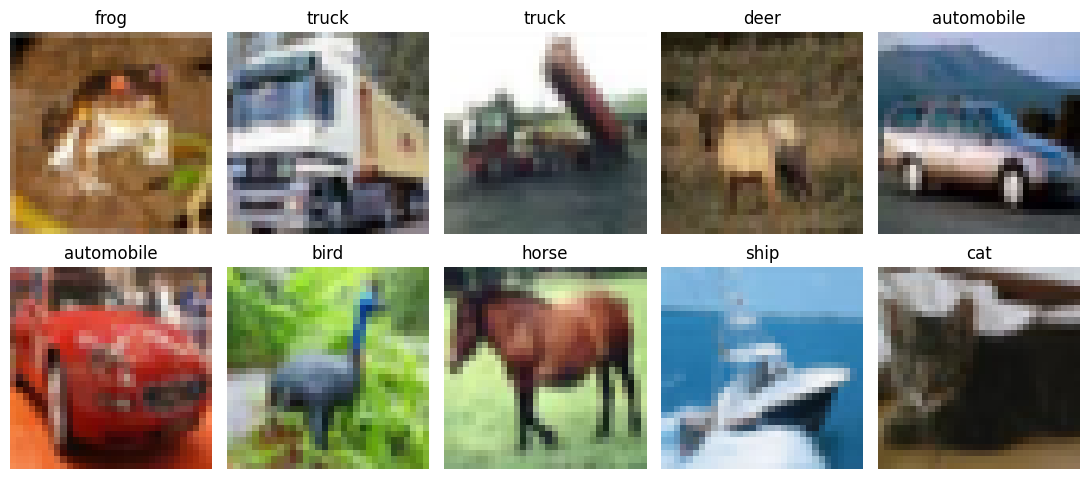

In [20]:
# I checked a few images to see the classes and colors.
fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for i, ax in enumerate(axes.flat):
    image, target = train_data[i]

    # I reversed normalization to display the original colors.
    image = image * torch.tensor(
        [0.2470, 0.2435, 0.2616]
    )[:, None, None]

    image = image + torch.tensor(
        [0.4914, 0.4822, 0.4465]
    )[:, None, None]

    ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(class_names[target])
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Building the Models

### LeNet-Style CNN

For my first model, I used a LeNet-style CNN with two convolution layers. I added ReLU and max pooling after each convolution.

The convolution layers help the model recognize patterns in the images. ReLU allows the model to learn more complex relationships, while pooling reduces the size of the feature maps.

I kept this architecture simple because I wanted to compare it with a model that uses more convolution layers.

### Mini-VGG

For my second model, I used Mini-VGG with four convolution layers arranged in two blocks.

Unlike LeNet-Style, Mini-VGG uses two smaller convolutions before each pooling layer. This allows the model to process the features more than once before reducing their size.

I used a smaller version of VGG to keep training manageable. Both models take 32 × 32 color images and produce scores for the ten CIFAR-10 classes.

In [21]:
class LeNetStyle(nn.Module):
    def __init__(self, width=1, dropout=0.2):
        super().__init__()

        c1 = int(16 * width)
        c2 = int(32 * width)

        # I used two convolution layers with pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, c1, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(c1, c2, 5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        # I used the extracted features to predict ten classes.
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(c2 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class MiniVGG(nn.Module):
    def __init__(self, width=1, dropout=0.2):
        super().__init__()

        c1 = int(16 * width)
        c2 = int(32 * width)

        # I placed two convolution layers before each pooling step.
        self.features = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(c1, c1, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(c1, c2, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(c2, c2, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(c2 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# I used one function to create either model.
def make_model(name, width=1, dropout=DROPOUT):
    if name == "LeNet-style":
        return LeNetStyle(width, dropout)
    return MiniVGG(width, dropout)


# I calculated the number of parameters and their memory size.
def model_stats(model):
    count = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    size_mb = count * 4 / (1024 ** 2)
    return count, size_mb


# I checked if the models produce ten class scores.
for name in ["LeNet-style", "Mini-VGG"]:
    model = make_model(name)
    output = model(torch.zeros(2, 3, 32, 32))

    print(name)
    print("Output shape:", tuple(output.shape))
    print("Parameters and weight memory:", model_stats(model))


LeNet-style
Output shape: (2, 10)
Parameters and weight memory: (47530, 0.18131256103515625)
Mini-VGG
Output shape: (2, 10)
Parameters and weight memory: (50138, 0.19126129150390625)


## 4. Training and Evaluation

I used the same training process for both models. During each epoch, the models make predictions, and I calculate the loss by comparing those predictions with the correct labels.

I used cross-entropy loss because each image belongs to one of ten classes. After calculating the loss, I used backpropagation to find the gradients and SGD with momentum to update the weights.

At the end of every epoch, I checked the validation accuracy and saved the weights whenever the result improved. This way, I could use the best version of each model instead of just keeping the final epoch.

I also recorded the training time, which includes the validation checks after each epoch. After training, I restored the best checkpoint and measured its training accuracy separately.

In [22]:
# I created separate loaders for training and validation.
def make_loader(indices, shuffle):
    return DataLoader(
        Subset(train_data, indices),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )


# I used this function to measure accuracy.
def evaluate(model, loader, collect=False):
    model.eval()

    correct = 0
    total = 0
    true_labels = []
    predictions = []

    # I don't update the model when measuring accuracy.
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            predicted = model(images).argmax(dim=1)

            correct += (predicted == targets).sum().item()
            total += targets.size(0)

            if collect:
                true_labels.extend(targets.cpu().tolist())
                predictions.extend(predicted.cpu().tolist())

    accuracy = 100 * correct / total

    if collect:
        return accuracy, true_labels, predictions

    return accuracy


# I trained each model and saved its best validation result.
def fit(name, train_indices, val_indices,
        width=1, dropout=DROPOUT,
        optimizer_name="SGD", epochs=EPOCHS):

    # I reset the seed before creating a new model.
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = make_model(name, width, dropout).to(DEVICE)

    train_loader = make_loader(train_indices, True)
    val_loader = make_loader(val_indices, False)
    train_eval_loader = make_loader(train_indices, False)

    loss_fn = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = optim.SGD(
            model.parameters(),
            lr=LEARNING_RATE,
            momentum=0.9
        )
    else:
        optimizer = optim.Adam(
            model.parameters(),
            lr=0.001
        )

    best_accuracy = -1
    best_state = None
    history = []

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()

        total_loss = 0
        seen = 0

        for images, targets in train_loader:
            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            # I clear the old gradients before each update.
            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_fn(outputs, targets)

            # I calculate gradients and update the weights.
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * targets.size(0)
            seen += targets.size(0)

        # I measure validation accuracy after each epoch.
        val_accuracy = evaluate(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": total_loss / seen,
            "val_accuracy": val_accuracy
        })

        # I keep the weights from the best validation epoch.
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            best_state = deepcopy({
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            })

        print(
            f"{name} | {optimizer_name} | "
            f"Epoch {epoch}/{epochs} | "
            f"Loss: {total_loss / seen:.3f} | "
            f"Validation: {val_accuracy:.2f}%"
        )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    seconds = time.perf_counter() - start

    model.load_state_dict(best_state)

    train_accuracy = evaluate(model, train_eval_loader)
    parameters, size_mb = model_stats(model)

    return {
        "model": model,
        "best_state": best_state,
        "val_accuracy": best_accuracy,
        "train_accuracy": train_accuracy,
        "time_seconds": seconds,
        "parameters": parameters,
        "size_mb": size_mb,
        "history": history
    }


## 5. Three-Fold Cross-Validation

I divided the 50,000 training images into three folds. I used stratified splitting so each fold would have a similar number of images from all ten classes.

In each run, I trained the model using two folds and validated it on the remaining fold. I repeated this three times for each architecture, using a new model each time.

I used the same folds for LeNet-Style and Mini-VGG so both models would be compared on the same data.

After completing all three folds, I selected the checkpoint with the highest validation accuracy from each architecture. These became my representative models for the test comparison.

In [23]:
# I created three folds using the training labels.
folds = list(
    StratifiedKFold(
        n_splits=FOLDS,
        shuffle=True,
        random_state=SEED
    ).split(np.arange(len(labels)), labels)
)

cv_rows = []
representatives = {}

# I trained both architectures on the same folds.
for name in ["LeNet-style", "Mini-VGG"]:
    fold_runs = []

    for fold_number, (train_idx, val_idx) in enumerate(
        folds, start=1
    ):
        print(f"\n{name} - Fold {fold_number}")

        result = fit(name, train_idx, val_idx)
        result["fold"] = fold_number

        fold_runs.append(result)

        cv_rows.append({
            "architecture": name,
            "fold": fold_number,
            "val_accuracy": result["val_accuracy"],
            "train_accuracy": result["train_accuracy"],
            "training_seconds": result["time_seconds"],
            "parameters": result["parameters"],
            "size_mb": result["size_mb"]
        })

    # I selected the checkpoint with the highest validation accuracy.
    best_run = max(
        fold_runs,
        key=lambda r: r["val_accuracy"]
    )

    representatives[name] = best_run

    print(
        f"Selected {name}: Fold {best_run['fold']}, "
        f"Validation: {best_run['val_accuracy']:.2f}%"
    )

cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

print("Mean validation accuracy:")
display(
    cv_table.groupby("architecture")["val_accuracy"]
    .agg(["mean", "std"])
    .round(2)
)



LeNet-style - Fold 1
LeNet-style | SGD | Epoch 1/8 | Loss: 1.792 | Validation: 46.18%
LeNet-style | SGD | Epoch 2/8 | Loss: 1.399 | Validation: 53.51%
LeNet-style | SGD | Epoch 3/8 | Loss: 1.228 | Validation: 57.62%
LeNet-style | SGD | Epoch 4/8 | Loss: 1.107 | Validation: 62.54%
LeNet-style | SGD | Epoch 5/8 | Loss: 1.030 | Validation: 63.26%
LeNet-style | SGD | Epoch 6/8 | Loss: 0.974 | Validation: 65.09%
LeNet-style | SGD | Epoch 7/8 | Loss: 0.918 | Validation: 65.61%
LeNet-style | SGD | Epoch 8/8 | Loss: 0.870 | Validation: 68.82%

LeNet-style - Fold 2
LeNet-style | SGD | Epoch 1/8 | Loss: 1.811 | Validation: 46.60%
LeNet-style | SGD | Epoch 2/8 | Loss: 1.411 | Validation: 54.92%
LeNet-style | SGD | Epoch 3/8 | Loss: 1.233 | Validation: 60.48%
LeNet-style | SGD | Epoch 4/8 | Loss: 1.122 | Validation: 63.72%
LeNet-style | SGD | Epoch 5/8 | Loss: 1.029 | Validation: 64.32%
LeNet-style | SGD | Epoch 6/8 | Loss: 0.970 | Validation: 65.45%
LeNet-style | SGD | Epoch 7/8 | Loss: 0.910 | 

,architecture,fold,val_accuracy,train_accuracy,training_seconds,parameters,size_mb
0,LeNet-style,1,68.819,75.277,92.180,47530,0.181
1,LeNet-style,2,68.123,74.383,92.008,47530,0.181
2,LeNet-style,3,67.263,72.212,91.582,47530,0.181
3,Mini-VGG,1,66.785,71.350,94.370,50138,0.191
4,Mini-VGG,2,68.867,73.423,93.293,50138,0.191
5,Mini-VGG,3,67.695,71.138,93.010,50138,0.191


Mean validation accuracy:


,mean,std
architecture,,
LeNet-style,68.07,0.78
Mini-VGG,67.78,1.04


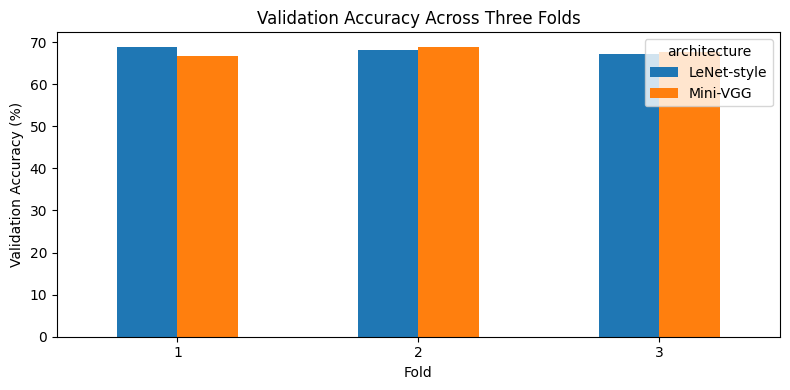

In [24]:
# I plotted the validation results for all three folds.
ax = cv_table.pivot(
    index="fold",
    columns="architecture",
    values="val_accuracy"
).plot(
    kind="bar",
    figsize=(8, 4),
    rot=0,
    title="Validation Accuracy Across Three Folds"
)

ax.set_xlabel("Fold")
ax.set_ylabel("Validation Accuracy (%)")

plt.tight_layout()
plt.show()


### Cross-Validation Results

LeNet-Style reached its highest validation accuracy of 68.82% on Fold 1, while Mini-VGG reached 68.87% on Fold 2.

Across all three folds, LeNet-Style achieved an average validation accuracy of 68.07%, compared to 67.78% for Mini-VGG.

LeNet-Style had a slightly higher average validation accuracy, but Mini-VGG achieved the highest individual validation result. I selected Fold 1 for LeNet-Style and Fold 2 for Mini-VGG because they had the best validation accuracy within their respective architectures.

I then used these two representative models for the final test comparison.

## 6. Comparing the Representative Models

After selecting one model from each architecture, I evaluated both on the 10,000 test images.

I compared their training accuracy, validation accuracy, test accuracy, number of parameters, and training time.

I also looked at confusion matrices because I wanted to see which classes the models had trouble identifying, instead of only looking at their overall accuracy.

In [25]:
# I created a separate loader for the test images.
test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

summary_rows = []
test_predictions = {}

for name, rep in representatives.items():
    test_accuracy, truth, predicted = evaluate(
        rep["model"],
        test_loader,
        collect=True
    )

    test_predictions[name] = (truth, predicted)

    summary_rows.append({
        "architecture": name,
        "selected_fold": rep["fold"],
        "train_accuracy_%": rep["train_accuracy"],
        "val_accuracy_%": rep["val_accuracy"],
        "test_accuracy_%": test_accuracy,
        "representative_training_s": rep["time_seconds"],
        "total_CV_training_s": cv_table.loc[
            cv_table["architecture"] == name,
            "training_seconds"
        ].sum(),
        "parameters": rep["parameters"],
        "model_size_MB_float32": rep["size_mb"]
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table.round(3))

# I chose the model with higher test accuracy for Part 2.
winner = summary_table.sort_values(
    "test_accuracy_%",
    ascending=False
).iloc[0]["architecture"]

print("Winning model:", winner)


,architecture,selected_fold,train_accuracy_%,val_accuracy_%,test_accuracy_%,representative_training_s,total_CV_training_s,parameters,model_size_MB_float32
0,LeNet-style,1,75.277,68.819,68.65,92.180,275.770,47530,0.181
1,Mini-VGG,2,73.423,68.867,69.24,93.293,280.673,50138,0.191


Winning model: Mini-VGG


### Test Results

| Measurement | LeNet-Style | Mini-VGG |
|---|---:|---:|
| Selected fold | 1 | 2 |
| Training accuracy | 75.28% | 73.42% |
| Validation accuracy | 68.82% | 68.87% |
| Test accuracy | 68.65% | 69.24% |
| Trainable parameters | 47,530 | 50,138 |
| Estimated weight memory | 0.181 MiB | 0.191 MiB |
| Training time | 92.18 s | 93.29 s |

Mini-VGG achieved 69.24% test accuracy, while LeNet-Style reached 68.65%.

Mini-VGG performed slightly better on the test set, with a difference of 0.59 percentage points. However, LeNet-Style had fewer parameters and trained slightly faster.

I found the results interesting because LeNet-Style had a higher average validation accuracy across the three folds, but Mini-VGG performed better on the test set.

Since Mini-VGG achieved the higher test accuracy, I selected it for the remaining experiments.

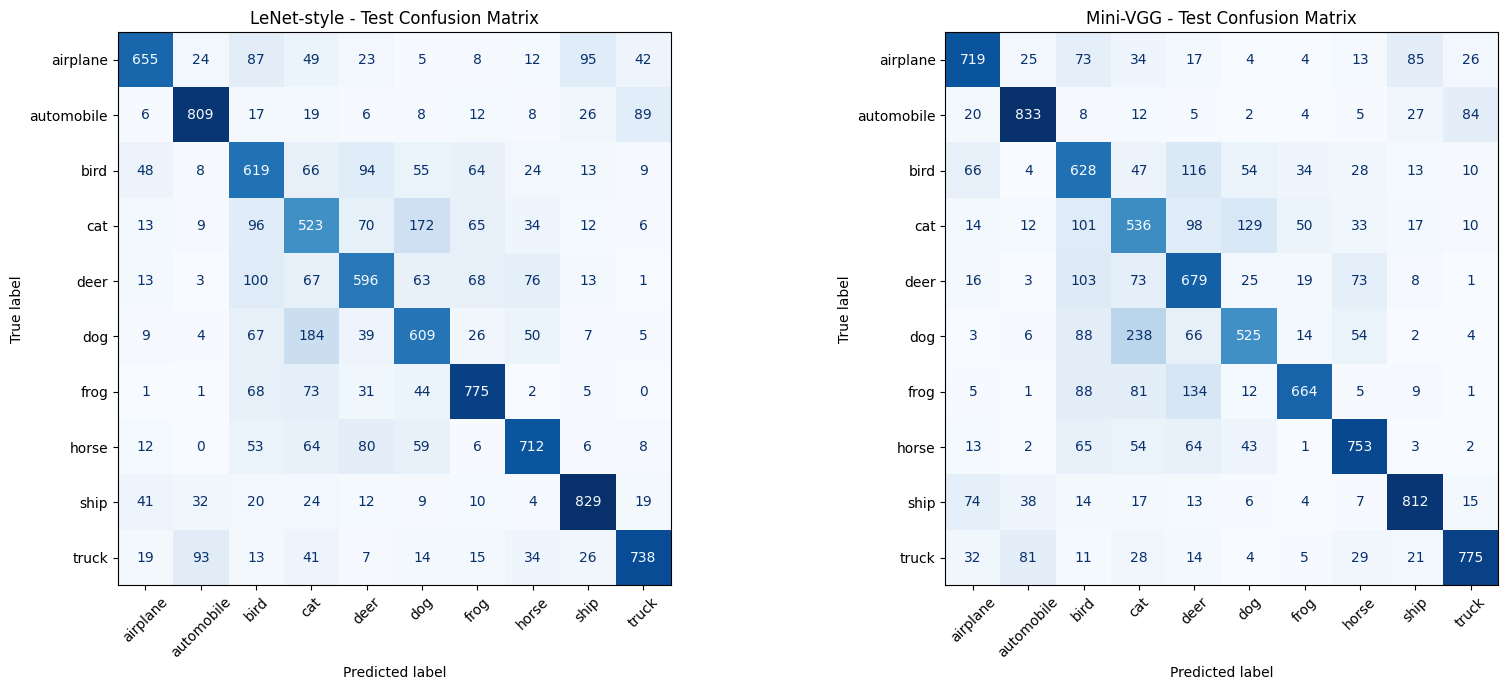

In [26]:
# I drew confusion matrices to see the classification mistakes.
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, name in zip(
    axes,
    ["LeNet-style", "Mini-VGG"]
):
    truth, predicted = test_predictions[name]

    cm = confusion_matrix(
        truth,
        predicted,
        labels=list(range(10))
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=class_names
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"{name} - Test Confusion Matrix")

plt.tight_layout()
plt.show()


In [27]:
# I checked which two classes the winning model confused most.
true_labels, predicted_labels = test_predictions[winner]

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=list(range(10))
)

# I ignore the diagonal because those are correct predictions.
np.fill_diagonal(cm, 0)

i, j = np.unravel_index(
    np.argmax(cm),
    cm.shape
)

print(
    f"Most common mistake: {class_names[i]} "
    f"predicted as {class_names[j]} "
    f"({cm[i, j]} images)"
)


Most common mistake: dog predicted as cat (238 images)


### Understanding the Classification Errors

I used the confusion matrices to see which classes the models had difficulty recognizing.

The diagonal values show correct predictions, while the other values show where the models made mistakes.

For the winning Mini-VGG model, the most common mistake was predicting dogs as cats. This happened 238 times.

I think the small size of CIFAR-10 images might make it harder to distinguish animals with similar shapes, colors, and textures.

The confusion matrices helped me identify which classes were more difficult for the models, although they cannot explain exactly why individual predictions were wrong.

## 7. Testing Changes to Mini-VGG

Mini-VGG achieved the higher test accuracy, so I used it for the next three experiments.

I wanted to see how changing the model size, dropout rate, and optimizer would affect its performance.

I tested these changes separately and kept the same training and validation split. This made it easier to compare the results without changing several settings at once.

I used validation accuracy for these comparisons and did not repeat the full three-fold process for each experiment.

### 7.1 Changing Model Complexity

I first tested whether changing the size of Mini-VGG would improve accuracy.

I made three versions of the model by changing the number of channels in the convolution layers. The smaller model used half the original number of channels, while the larger model used twice as many.

I kept the same number of layers and training settings so I could focus on how model size affected performance.

In [34]:
# I used the same fold as my selected Mini-VGG model.
winner_fold = representatives[winner]["fold"]
train_idx, val_idx = folds[winner_fold - 1]

baseline = representatives[winner]
part2_rows = []

# I store the results of each experiment in one table.
def add_row(experiment, setting, result):
    part2_rows.append({
        "experiment": experiment,
        "setting": setting,
        "val_accuracy_%": result["val_accuracy"],
        "train_accuracy_%": result["train_accuracy"],
        "parameters": result["parameters"],
        "time_seconds": result["time_seconds"]
    })


# I reuse the original model as my baseline.
add_row("Complexity", "Original (1x)", baseline)

# I trained smaller and larger versions of Mini-VGG.
for width, label in [
    (0.5, "Smaller (0.5x)"),
    (2, "Larger (2x)")
]:
    print("\nTesting:", label)

    result = fit(
        winner,
        train_idx,
        val_idx,
        width=width
    )

    add_row("Complexity", label, result)

display(pd.DataFrame(part2_rows).round(3))



Testing: Smaller (0.5x)
Mini-VGG | SGD | Epoch 1/8 | Loss: 2.131 | Validation: 32.57%
Mini-VGG | SGD | Epoch 2/8 | Loss: 1.735 | Validation: 41.92%
Mini-VGG | SGD | Epoch 3/8 | Loss: 1.533 | Validation: 49.07%
Mini-VGG | SGD | Epoch 4/8 | Loss: 1.372 | Validation: 54.72%
Mini-VGG | SGD | Epoch 5/8 | Loss: 1.263 | Validation: 58.35%
Mini-VGG | SGD | Epoch 6/8 | Loss: 1.174 | Validation: 59.89%
Mini-VGG | SGD | Epoch 7/8 | Loss: 1.122 | Validation: 62.49%
Mini-VGG | SGD | Epoch 8/8 | Loss: 1.062 | Validation: 64.35%

Testing: Larger (2x)
Mini-VGG | SGD | Epoch 1/8 | Loss: 1.969 | Validation: 39.46%
Mini-VGG | SGD | Epoch 2/8 | Loss: 1.503 | Validation: 48.89%
Mini-VGG | SGD | Epoch 3/8 | Loss: 1.286 | Validation: 60.41%
Mini-VGG | SGD | Epoch 4/8 | Loss: 1.110 | Validation: 63.65%
Mini-VGG | SGD | Epoch 5/8 | Loss: 0.978 | Validation: 67.94%
Mini-VGG | SGD | Epoch 6/8 | Loss: 0.874 | Validation: 71.16%
Mini-VGG | SGD | Epoch 7/8 | Loss: 0.801 | Validation: 71.46%
Mini-VGG | SGD | Epoch 

,experiment,setting,val_accuracy_%,train_accuracy_%,parameters,time_seconds
0,Complexity,Original (1x),68.867,73.423,50138,93.293
1,Complexity,Smaller (0.5x),64.355,66.913,21394,89.168
2,Complexity,Larger (2x),72.071,77.146,131818,94.152


### Model Complexity Results

| Model size | Parameters | Validation accuracy |
|---|---:|---:|
| Smaller (0.5×) | 21,394 | 64.36% |
| Original (1×) | 50,138 | 68.87% |
| Larger (2×) | 131,818 | 72.07% |

The larger Mini-VGG achieved the highest validation accuracy at 72.07%, compared to 68.87% for the original model.

The smaller model reached 64.36%. Increasing the number of convolution channels improved validation accuracy by about 3.20 percentage points compared to the original model.

**Conclusion: Yes, increasing model complexity improved validation accuracy in this experiment.**

However, the larger model also required more parameters, so improving accuracy came with a higher model complexity.

### 7.2 Changing the Dropout Rate

Next, I tested whether changing dropout would improve Mini-VGG's performance.

Dropout randomly disables some units during training, which can help reduce overfitting.

The original model used dropout 0.2. I compared it with no dropout and a higher rate of 0.4.

I kept the other training settings the same to see how these different dropout rates affected validation accuracy.

In [35]:
# I compare the original dropout with two other settings.
add_row("Regularization", "Dropout 0.2", baseline)

for dropout in [0.0, 0.4]:
    print("\nTesting dropout:", dropout)

    result = fit(
        winner,
        train_idx,
        val_idx,
        dropout=dropout
    )

    add_row(
        "Regularization",
        f"Dropout {dropout}",
        result
    )

display(pd.DataFrame(part2_rows).round(3))



Testing dropout: 0.0
Mini-VGG | SGD | Epoch 1/8 | Loss: 2.020 | Validation: 40.13%
Mini-VGG | SGD | Epoch 2/8 | Loss: 1.516 | Validation: 49.69%
Mini-VGG | SGD | Epoch 3/8 | Loss: 1.280 | Validation: 55.03%
Mini-VGG | SGD | Epoch 4/8 | Loss: 1.096 | Validation: 60.34%
Mini-VGG | SGD | Epoch 5/8 | Loss: 0.989 | Validation: 66.35%
Mini-VGG | SGD | Epoch 6/8 | Loss: 0.906 | Validation: 67.73%
Mini-VGG | SGD | Epoch 7/8 | Loss: 0.831 | Validation: 68.48%
Mini-VGG | SGD | Epoch 8/8 | Loss: 0.771 | Validation: 67.17%

Testing dropout: 0.4
Mini-VGG | SGD | Epoch 1/8 | Loss: 2.087 | Validation: 36.05%
Mini-VGG | SGD | Epoch 2/8 | Loss: 1.671 | Validation: 46.61%
Mini-VGG | SGD | Epoch 3/8 | Loss: 1.480 | Validation: 52.50%
Mini-VGG | SGD | Epoch 4/8 | Loss: 1.328 | Validation: 59.06%
Mini-VGG | SGD | Epoch 5/8 | Loss: 1.210 | Validation: 61.62%
Mini-VGG | SGD | Epoch 6/8 | Loss: 1.108 | Validation: 64.27%
Mini-VGG | SGD | Epoch 7/8 | Loss: 1.037 | Validation: 66.98%
Mini-VGG | SGD | Epoch 8/8

,experiment,setting,val_accuracy_%,train_accuracy_%,parameters,time_seconds
0,Complexity,Original (1x),68.867,73.423,50138,93.293
1,Complexity,Smaller (0.5x),64.355,66.913,21394,89.168
2,Complexity,Larger (2x),72.071,77.146,131818,94.152
3,Regularization,Dropout 0.2,68.867,73.423,50138,93.293
4,Regularization,Dropout 0.0,68.477,72.907,50138,91.308
5,Regularization,Dropout 0.4,67.805,71.236,50138,91.729


### Regularization Results

| Dropout rate | Training accuracy | Validation accuracy |
|---|---:|---:|
| 0.0 | 72.91% | 68.48% |
| 0.2 | 73.42% | 68.87% |
| 0.4 | 71.24% | 67.81% |

The original dropout rate of 0.2 achieved the highest validation accuracy at 68.87%.

Removing dropout slightly reduced accuracy to 68.48%, while increasing dropout to 0.4 reduced accuracy further to 67.81%.

**Conclusion: Moderate dropout helped in this experiment, but stronger regularization did not improve performance.**

This suggests that the effect of dropout depends on how much regularization is used. More dropout does not always produce better results.

### 7.3 Comparing SGD and Adam

For my final experiment, I compared SGD with momentum and Adam.

I originally trained Mini-VGG using SGD. I wanted to see whether switching to Adam would improve validation accuracy.

I kept the same model, data split, dropout rate, and number of epochs.

I used a learning rate of 0.02 for SGD and 0.001 for Adam, so this comparison reflects the specific optimizer configurations I tested rather than the optimizer algorithms alone.

In [36]:
# I compare the original SGD model with a new Adam model.
add_row("Optimizer", "SGD", baseline)

print("\nTraining with Adam")

adam_result = fit(
    winner,
    train_idx,
    val_idx,
    optimizer_name="Adam"
)

add_row("Optimizer", "Adam", adam_result)

part2_table = pd.DataFrame(part2_rows)
display(part2_table.round(3))



Training with Adam
Mini-VGG | Adam | Epoch 1/8 | Loss: 1.799 | Validation: 45.95%
Mini-VGG | Adam | Epoch 2/8 | Loss: 1.484 | Validation: 50.98%
Mini-VGG | Adam | Epoch 3/8 | Loss: 1.370 | Validation: 53.81%
Mini-VGG | Adam | Epoch 4/8 | Loss: 1.280 | Validation: 56.60%
Mini-VGG | Adam | Epoch 5/8 | Loss: 1.203 | Validation: 59.36%
Mini-VGG | Adam | Epoch 6/8 | Loss: 1.126 | Validation: 61.43%
Mini-VGG | Adam | Epoch 7/8 | Loss: 1.069 | Validation: 63.66%
Mini-VGG | Adam | Epoch 8/8 | Loss: 1.019 | Validation: 65.91%


,experiment,setting,val_accuracy_%,train_accuracy_%,parameters,time_seconds
0,Complexity,Original (1x),68.867,73.423,50138,93.293
1,Complexity,Smaller (0.5x),64.355,66.913,21394,89.168
2,Complexity,Larger (2x),72.071,77.146,131818,94.152
3,Regularization,Dropout 0.2,68.867,73.423,50138,93.293
4,Regularization,Dropout 0.0,68.477,72.907,50138,91.308
5,Regularization,Dropout 0.4,67.805,71.236,50138,91.729
6,Optimizer,SGD,68.867,73.423,50138,93.293
7,Optimizer,Adam,65.915,68.923,50138,90.971


### Optimizer Results

| Optimizer | Training accuracy | Validation accuracy |
|---|---:|---:|
| SGD with momentum | 73.42% | 68.87% |
| Adam | 68.92% | 65.92% |

SGD achieved higher validation accuracy than Adam in this experiment.

With SGD, Mini-VGG reached 68.87%, while Adam reached 65.92%.

**Conclusion: No, switching from SGD to Adam did not improve performance under these settings.**

Since the learning rates were different, this comparison does not prove that SGD is always better than Adam. Different learning rates or longer training could produce different results.

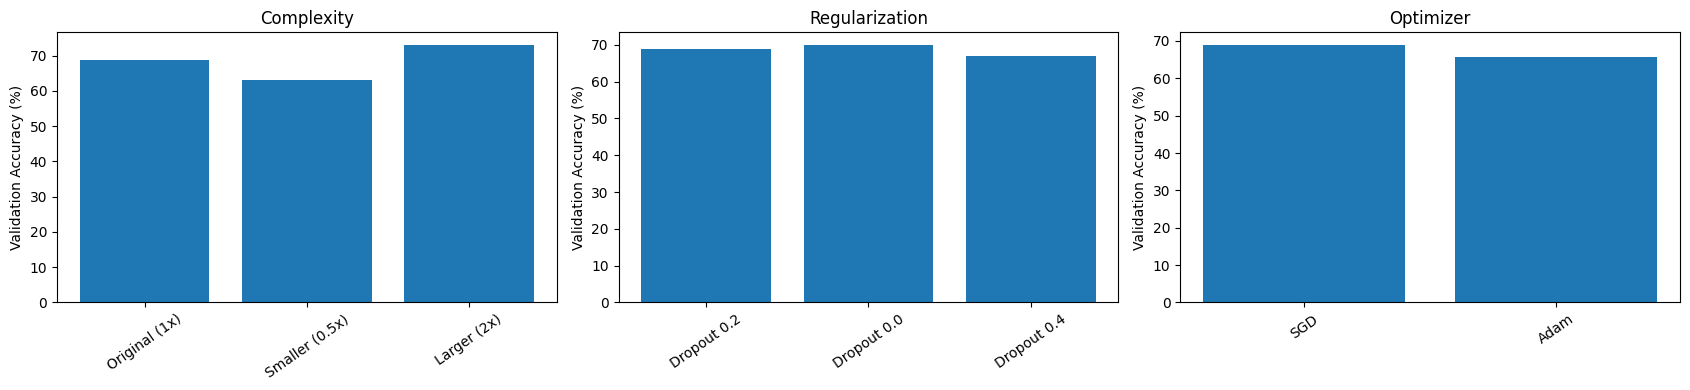

Results saved.


In [31]:
# I plotted the results of the three experiments.
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

for ax, experiment in zip(
    axes,
    ["Complexity", "Regularization", "Optimizer"]
):
    results = part2_table[
        part2_table["experiment"] == experiment
    ]

    ax.bar(
        results["setting"],
        results["val_accuracy_%"]
    )

    ax.set_title(experiment)
    ax.set_ylabel("Validation Accuracy (%)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


# I saved the result tables for my report.
cv_table.to_csv("part1_folds.csv", index=False)
summary_table.to_csv("part1_representatives.csv", index=False)
part2_table.to_csv("part2_hypotheses.csv", index=False)

print("Results saved.")


## 8. Final Discussion

After comparing LeNet-Style and Mini-VGG, I found that their performance was fairly close.

LeNet-Style had a slightly higher average validation accuracy across the three folds, but Mini-VGG achieved the higher test accuracy at 69.24%, compared to 68.65% for LeNet-Style.

The difference was only 0.59 percentage points, so I cannot conclude that one architecture is clearly better overall from this experiment alone.

I selected Mini-VGG for the additional experiments because it achieved the higher test accuracy.

Increasing the number of convolution channels improved Mini-VGG's validation accuracy from 68.87% to 72.07%. The larger version performed better, although it also required more parameters.

For regularization, dropout 0.2 produced the highest validation accuracy at 68.87%. Removing dropout or increasing it to 0.4 gave slightly worse results.

SGD also performed better than Adam with the learning rates I tested.

What I found most interesting was that the results did not always match my expectations. A larger model helped, but stronger regularization and switching optimizers did not automatically improve performance.

These experiments helped me understand why it is important to compare models and training settings using actual results rather than assuming that one approach will always work better.

### Limitations

I trained each model for eight epochs, so longer training could produce different results.

I also used only one validation fold for the additional experiments instead of repeating the full three-fold process. I did not test multiple random seeds or use data augmentation.

Because of these limitations, my conclusions describe the results of this particular experiment rather than general rules about CNN performance.

## 9. References

1. PyTorch. *Training a Classifier: CIFAR-10.*  
   https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html

2. CS 436/536. *Lecture 11–12: Deep Learning and Convolutional Neural Networks.*